<img src="http://imgur.com/1ZcRyrc.png" style="float: left; margin: 20px; height: 55px">

# Optimizing NN Models

---

_Created by: Mohamad Hindi_

## Loss Landscape

**What it is**:
- A loss landscape is a visual representation of how a model's loss changes as we adjust its weights.
- In the 3D loss landscape:

    - X-axis (Parameter 1): Weight \(w_1\)
    - Y-axis (Parameter 2): Weight \(w_2\)
    - Z-axis: Loss calculated using those weight
    
**Landscape samples**:
- Access [this](https://www.hackerstreak.com/articles/visualize-loss-landscape/) link

## The Neuron Math

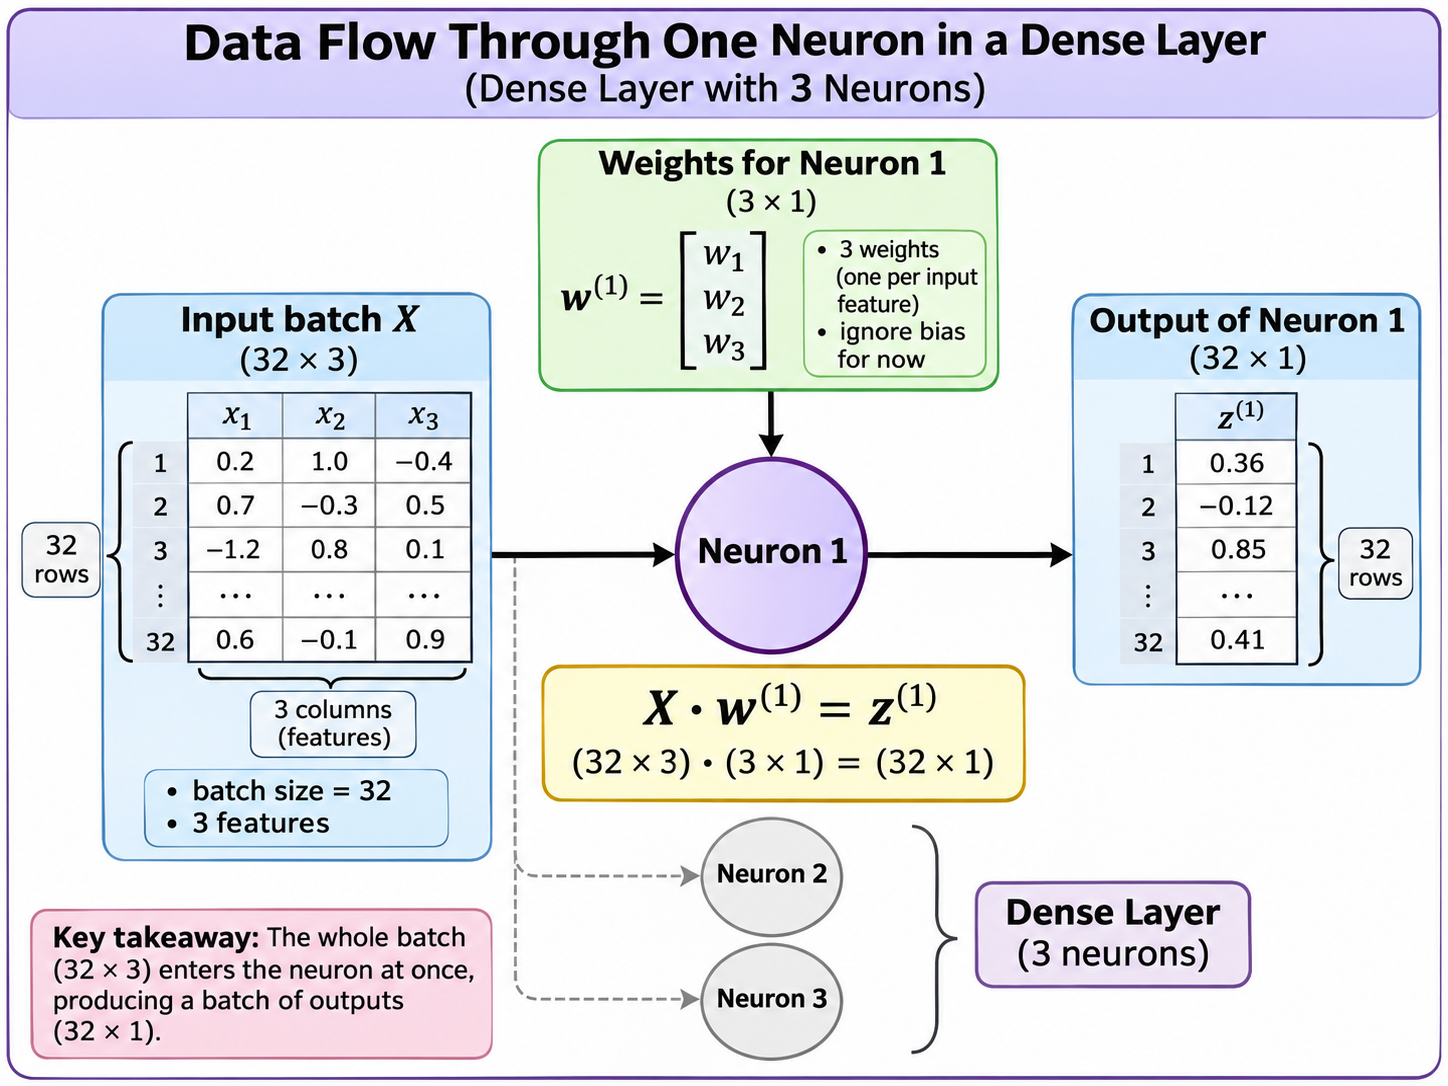

## Setup

In [1]:
import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from keras.datasets import fashion_mnist

from keras.models import Sequential
from keras.layers import Dense, Input, Flatten

from keras.callbacks import EarlyStopping

from sklearn.metrics import accuracy_score, recall_score
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

from keras.utils import set_random_seed

# Global Settings
SEED = 42

## Load Data

Loading [Fashion_mnist dataset](https://www.tensorflow.org/datasets/catalog/fashion_mnist)

In [2]:
# Load data
(X_train_all, y_train_all), (X_test, y_test) = fashion_mnist.load_data()

## Split Data

In [3]:
# Split Train to train and val
# Let val size be same as test
X_train, X_val, y_train, y_val = train_test_split(X_train_all, 
                                                  y_train_all, 
                                                  test_size= 10_000, 
                                                  stratify=y_train_all,
                                                  random_state=42
                                                 )

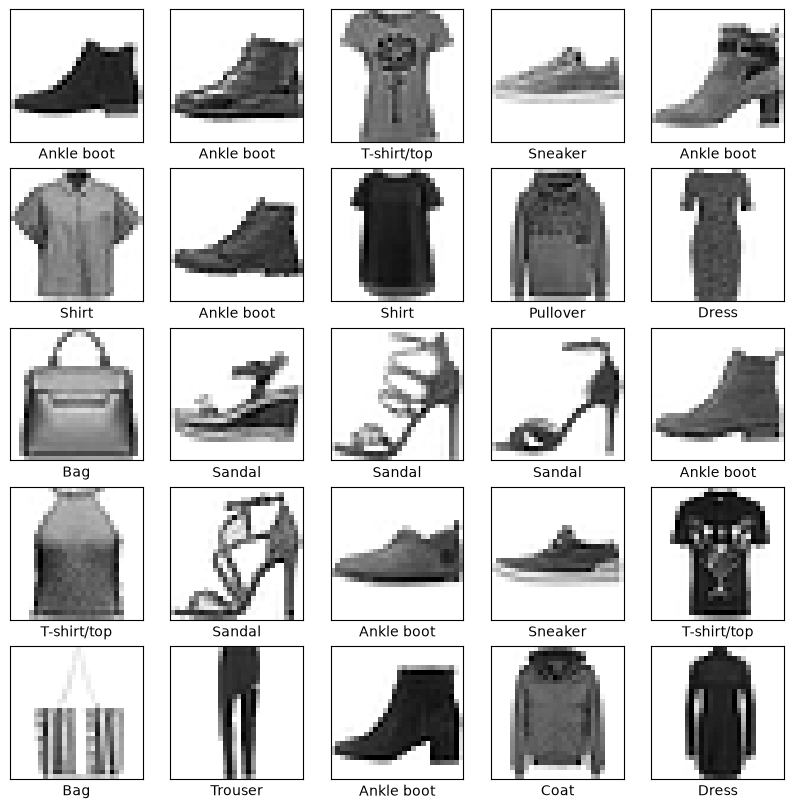

In [4]:
# The labels in Fashion MNIST are 0-9. We need to map them to names:

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

fig_fashion = plt.figure(figsize=(10, 10))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray_r")
    plt.xticks([])
    plt.yticks([])
    #plt.grid(False)
    # y_train[i] is the number; class_names[y_train[i]] is the word
    plt.xlabel(class_names[y_train[i]])
plt.show()

## Preprocess Data

In [5]:
# Manual MinMax Scaling
X_train = X_train/255
X_val = X_val/255
X_test = X_test/255


## First Model Attempt

In [6]:
# A seed controls a sequence of random numbers, not one fixed number.

# We reset the seed before creating each new model to ensure all models 
# start with the same random conditions, making comparisons fairer.
set_random_seed(SEED)

# Step 1: Architecture
model1 = Sequential([
    Input(shape=(28,28)),   # each image is 28x28
    Flatten(), # Converts a multi-dimensional image into a 1D vector to feed into Dense layers
    Dense(128, activation="relu"), # hidden layer
    Dense(64, activation="relu"), # hidden layer
    Dense(64, activation="relu"), # hidden layer
    Dense(32, activation="relu"), # hidden layer
    Dense(8, activation="relu"), # hidden layer
    Dense(10, activation='softmax') # neurons correspond to the number of labels
])

# Step2: Compile
model1.compile(loss='sparse_categorical_crossentropy',
              metrics=['acc'],  # or 'accuracy'
              optimizer='adam')


#Step3: Fitting

# configure EarlyStopping parameters
es=EarlyStopping(monitor='val_loss',
                 patience=5,
                 restore_best_weights=True
                )

history1 = model1.fit(X_train,
                    y_train,
                    validation_data=(X_val,y_val),
                    epochs=100,
                    batch_size=128,
                    callbacks=[es]
                   )

Epoch 1/100
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - acc: 0.7152 - loss: 0.8348 - val_acc: 0.8383 - val_loss: 0.4704
Epoch 2/100
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - acc: 0.8455 - loss: 0.4422 - val_acc: 0.8534 - val_loss: 0.4125
Epoch 3/100
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - acc: 0.8620 - loss: 0.3858 - val_acc: 0.8696 - val_loss: 0.3623
Epoch 4/100
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - acc: 0.8715 - loss: 0.3546 - val_acc: 0.8765 - val_loss: 0.3536
Epoch 5/100
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - acc: 0.8793 - loss: 0.3312 - val_acc: 0.8800 - val_loss: 0.3394
Epoch 6/100
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - acc: 0.8861 - loss: 0.3124 - val_acc: 0.8813 - val_loss: 0.3333
Epoch 7/100
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - acc: 0.8908 - loss: 0.2988 - val_acc: 0.8839 - val_loss: 0.3274
Epoch 8/100
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - acc: 0.8944 - loss: 0.2871 - val_acc: 0.8824 - val_loss: 0.3262
Epoch 9/100
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/

In [7]:
# Summary
model1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │            90 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 345,992 (1.32 MB)

 Trainable params: 115,330 (450.51 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 230,662 (901.03 KB)

In [1]:
# History dataframe
history1_df=pd.DataFrame(history1.history)
history1_df.head()

NameError: name 'pd' is not defined

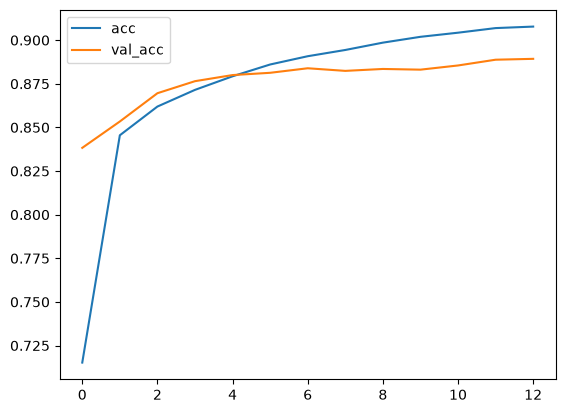

In [9]:
# Plot train and validation accuracy 
history1_df[['acc','val_acc']].plot();

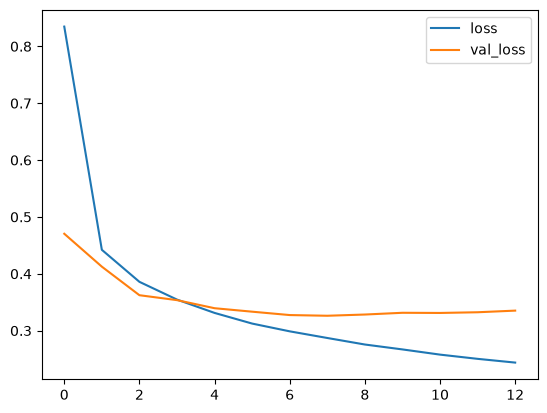

In [10]:
# Plot train and validation loss as bar chart
history1_df[['loss','val_loss']].plot();


## Evaluating the Model

### Predictions

In [11]:
# Predict on X_test
y_pred1 = model1.predict(X_test)
y_pred1

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


array([[9.2955964e-04, 1.1541357e-11, 3.6652604e-12, ..., 3.2052595e-02,
        4.4661815e-07, 9.6616292e-01],
       [6.5499284e-05, 3.6220588e-10, 9.8793054e-01, ..., 2.0468565e-09,
        1.4214609e-05, 3.9354829e-13],
       [2.2590211e-08, 9.9999034e-01, 5.7621865e-13, ..., 2.7630092e-24,
        7.2794660e-06, 1.2003701e-16],
       ...,
       [3.1848270e-03, 3.7175134e-05, 3.0658194e-03, ..., 3.6697583e-07,
        9.3976653e-01, 7.3621420e-09],
       [1.4116199e-06, 9.9987602e-01, 7.8305568e-10, ..., 2.0147915e-19,
        7.0696959e-05, 3.1594004e-13],
       [6.6930760e-08, 8.1375989e-11, 2.3349391e-09, ..., 6.8109273e-03,
        1.2060045e-03, 2.1456053e-05]], shape=(10000, 10), dtype=float32)

In [12]:
# Convert predictions to labels
y_pred_label1= y_pred1.argmax(axis=1)
y_pred_label1

array([9, 2, 1, ..., 8, 1, 5], shape=(10000,))

### Evaluation

In [13]:
model1.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.8705 - loss: 0.3631


[0.363144189119339, 0.8705000281333923]

### Error Analysis

In [14]:
# Classification Report
print( classification_report(y_test,y_pred_label1) )

              precision    recall  f1-score   support

           0       0.89      0.74      0.81      1000
           1       0.99      0.96      0.97      1000
           2       0.75      0.83      0.79      1000
           3       0.83      0.91      0.87      1000
           4       0.82      0.73      0.77      1000
           5       0.97      0.95      0.96      1000
           6       0.65      0.71      0.68      1000
           7       0.91      0.98      0.94      1000
           8       0.97      0.97      0.97      1000
           9       0.97      0.92      0.94      1000

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000



In [15]:
# Confusion Matrix
conf_matrix1 = confusion_matrix(y_test,y_pred_label1)
conf_matrix1

array([[738,   4,  17,  53,   2,   0, 174,   1,  10,   1],
       [  0, 960,   1,  29,   5,   0,   4,   0,   1,   0],
       [  7,   1, 833,  17,  62,   0,  78,   0,   2,   0],
       [ 10,   6,  12, 907,  34,   0,  25,   0,   6,   0],
       [  0,   2, 136,  37, 735,   0,  88,   0,   2,   0],
       [  0,   0,   0,   0,   0, 954,   0,  33,   2,  11],
       [ 76,   1, 104,  41,  55,   0, 714,   0,   9,   0],
       [  0,   0,   0,   0,   0,  10,   0, 976,   0,  14],
       [  2,   0,   3,   7,   4,   2,   9,   3, 970,   0],
       [  0,   0,   0,   1,   0,  17,   0,  63,   1, 918]])

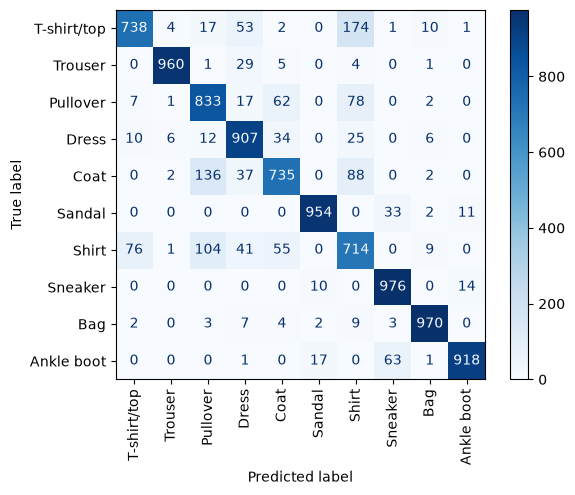

In [16]:
# ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test,
                                        y_pred_label1,
                                        display_labels=class_names,
                                        xticks_rotation=90,    
                                        cmap="Blues");


---
# Making Our Dense Neural Network Better 🚀

We will now **optimize** the *same network* above, step by step. 

> **No CNNs, convolutions, transfer learning, or advanced computer vision layers for now.**

## Some Optimization Techniques:

1. **Regularization (L1 and L2)** — discourage overly complicated weight values.
2. **Dropout** — make a model less dependent on individual neurons.
3. **Early Stopping** — prevent the model from overfitting
3. **Batch Normalization** — make hidden-layer activations easier to optimize.
4. **Choosing an optimizer** — compare SGD + momentum, RMSprop, Adam, and AdamW.
5. **Learning-rate schedules** — change `alpha` while training instead of fixing it forever.



> **Important:** Adding a new technique is not guaranteed to improve accuracy. The point is to understand when and why it helps.

---
## 1.  Regularization

**Why do large weights lead to overfitting?** 
- Large weights can make the model overly sensitive to small changes in inputs, allowing it to fit noise and outliers instead of general patterns.
    
**Where to Apply Regularization:**
- `kernel_regularizer`: Penalizes large weights. Most commonly used.
- `bias_regularizer`: Penalizes large biases. Rarely needed.
- `activity_regularizer`: Penalizes large neuron outputs (activations), encouraging smaller or sparser activations.

**Regularization Strength (λ — Lambda):**
- Controls how strongly the model penalizes weights, biases, or activations.
- **Higher λ:** Stronger penalty → greater risk of underfitting.
- **Lower λ:** Weaker penalty → greater risk of overfitting.
- Common values to experiment with: `0.0001`, `0.001`, `0.01`.
- Best λ is determined by validation performance.

In [ ]:
# ----------------------------------
# MODEL 2 — Model 1 + Regularization
# ----------------------------------

from keras.________ import ________

??

# Step 1: Architecture
model2 = Sequential([
    Input(shape=(28,28)),   
    Flatten(), 
    Dense(128, activation="relu"), 
    Dense(64, activation="relu" ), 
    Dense(64, activation="relu" ), 
    Dense(32, activation="relu" ), 
    Dense(8, activation="relu"), 
    Dense(10, activation='softmax') 
])

# Step2: Compile
model2.compile(loss='sparse_categorical_crossentropy',
              metrics=['acc'],  # or 'accuracy'
              optimizer='adam')


#Step3: Fitting

es=EarlyStopping(monitor='val_loss',
                 patience=5,
                 restore_best_weights=True
                )

history2 = model2.fit(X_train,
                    y_train,
                    validation_data=(X_val,y_val),
                    epochs=100,
                    batch_size=128,
                    callbacks=[es]
                   )

In [ ]:
# Evaluation function
def eval_results (m, h):
    history_df = pd.DataFrame(h.history)
    history_df[['loss','val_loss']].plot();
    history_df[['acc','val_acc']].plot();
    y_pred = m.predict(X_test)
    y_pred_label= y_pred.argmax(axis=1)
    print( classification_report(y_test,y_pred_label) )
    ConfusionMatrixDisplay.from_predictions(y_test,
                                        y_pred_label,
                                        display_labels=class_names,
                                        xticks_rotation=90,    
                                        cmap="Blues");


In [ ]:
# Evaluate current model
eval_results(model2, history2)

In [ ]:
# Compare with previous model
eval_results(model1, history1)

### Reflect

**What if Model 2 has lower training accuracy but higher validation accuracy?**

- That is often a **good result**. It suggests that the network is relying less on memorizing the training images and is generalizing more successfully.

**What if both training and validation accuracy drop?**

- Our regularization might be too strong. Apply regularization in fewer layers and decrease lambda

---
## 2. Dropout

**Dropout** is a regularization technique that temporarily turns **a random fraction of neuron outputs off** during training.

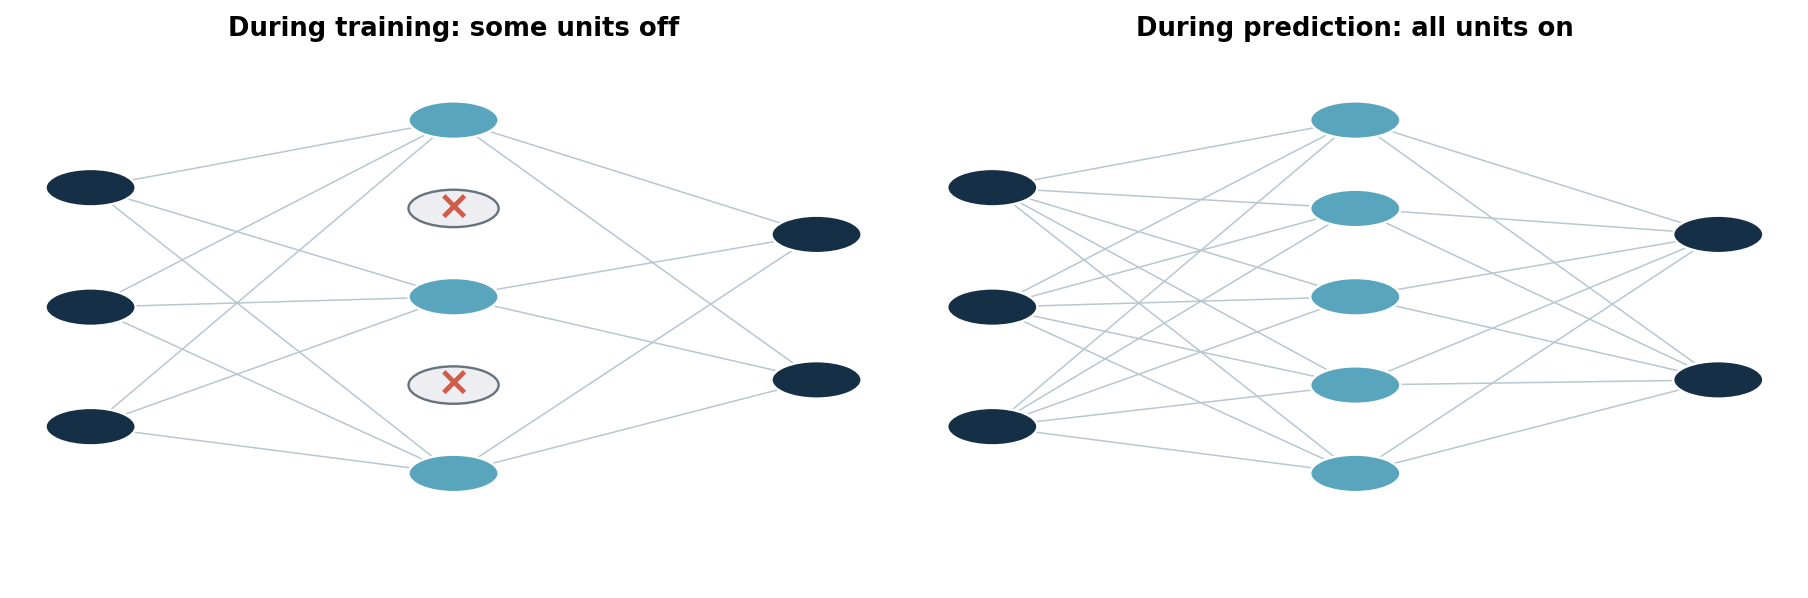

**How it works:**

- `Dropout(0.20)` means **20% of the layer's outputs** are randomly set to zero on each training pass.
- A **different random subset** can be disabled for the next batch.
- During **prediction**, dropout is switched **off**, so all learned neurons are available.

**When to use it**

- Especially useful when there is a **large gap** between training and validation performance.
- Common starting points for dense hidden layers include `0.1` to `0.3`.

**Difference from L2:** 
- L2 discourages *large weights*. 
- Dropout disrupts *which hidden units are available during training*. They address overfitting in different ways.

In [ ]:
# ----------------------------
# MODEL 3 — Model 2 + Dropout
# ----------------------------
from keras.________ import ________

set_random_seed(SEED)

# Step 1: Architecture
model3 = Sequential([
    Input(shape=(28,28)),  
    Flatten(),
    
    Dense(128, activation="relu", kernel_regularizer=l2(l=0.0001) ),
    
    Dense(64, activation="relu" , kernel_regularizer=l2(l=0.0001) ),
    
    Dense(64, activation="relu" , kernel_regularizer=l2(l=0.0001) ), 
    
    Dense(32, activation="relu" , kernel_regularizer=l2(l=0.0001) ), 
    
    Dense(8, activation="relu"), 
    
    Dense(10, activation='softmax') 
])

# Step2: Compile
model3.compile(loss='sparse_categorical_crossentropy',
              metrics=['acc'],  # or 'accuracy'
              optimizer='adam')


#Step3: Fitting

es=EarlyStopping(monitor='val_loss',
                 patience=5,
                 restore_best_weights=True
                )

history3 = model3.fit(X_train,
                    y_train,
                    validation_data=(X_val,y_val),
                    epochs=100,
                    batch_size=128,
                    callbacks=[es]
                   )

In [ ]:
# Model 3 evaluation
eval_results(model3, history3)

In [ ]:
# Model 2 evaluation again
eval_results(model2, history2)

---
# 3. Batch Normalization 

**What it is:** 
- It is a layer that normalizes the values flowing through a neural network. 
- Helps keep these values - the neuron outputs - at a consistent scale during training.

**Why it is used:**

- **Stabilizes Training:**
    - As weights change during training, the outputs of neurons can become very large, very small, or vary significantly between batches.
    - These changes can make it harder for the optimizer to determine appropriate weight updates, since the same weight change can have very different effects depending on the scale of the inputs.
    - Batch Normalization keeps these values at a more consistent scale, making optimization more stable and often allowing faster learning.


- **Reduces Dependence on Weight Initialization:**
    - Randomly initialized weights determine the initial outputs of neurons. Poor initial weights can produce values that are too large or too small, making training difficult.
    - Batch Normalization adjusts the scale of these outputs, reducing the impact of poorly scaled initial weights.
    - As a result, the network becomes less sensitive to weight initialization and can often train effectively from a wider range of starting weights.

**When to use it:**

- Particularly in **larger or deeper** networks.

In [ ]:
# --------------------------------------
# MODEL 4 — Model 3 + BatchNormalization
# --------------------------------------

from keras.layers import BatchNormalization, Activation

set_random_seed(SEED)

# Step 1: Architecture
model4 = Sequential([
    # Input Layer
    Input(shape=(28, 28)),
    Flatten(),
    
    # Hidden Layer #1
    Dense(128, activation="relu", kernel_regularizer=l2(0.0001)), 
    Dropout(0.3),          
    
    # Hidden Layer #2
    Dense(64, activation="relu", kernel_regularizer=l2(0.0001)),

    # Hidden Layer #3
    Dense(64, activation="relu", kernel_regularizer=l2(0.0001)),

    # Hidden Layer #4
    Dense(32, activation="relu", kernel_regularizer=l2(0.0001)),

    # Hidden Layer #5
    Dense(8, activation="relu"),

    # Output Layer
    Dense(10, activation="softmax")
])

# Step 2: Compile
model4.compile(
    loss="sparse_categorical_crossentropy",
    metrics=["acc"],
    optimizer="adam"
)

# Step 3: Fitting
es = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history4 = model4.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=128,
    callbacks=[es]
)

In [ ]:
# Model 4 evaluation
eval_results(model4, history4)

---
## 5. Optimizers

An **optimizer** decides **how to update the network's weights** using gradients calculated from the loss function. We already know that **learning rate** controls how large the updates are. Different optimizers go further by deciding **how to adjust those updates**.

### Three popular optimizers:

#### **📈 1. RMSprop (Root Mean Square Propagation)**

- **What it is:** An adaptive optimizer that adjusts the effective learning rate for each weight based on a moving average of its recent squared gradients.
- **Why it is popular:** Reduces the size of updates for weights that consistently receive large gradients, helping make optimization more stable.
- **Best used for:** A useful option for RNNs, LSTMs, reinforcement learning, and other neural networks. However, it is not automatically better for sequential data than Adam.

>RMSprop adjusts weight updates, but does not guarantee protection against exploding/vaninishing gradients.


#### **🥇 2. Adam (Adaptive Moment Estimation)**

- **What it is:** Combines two ideas: **Momentum**, which considers the direction of previous gradients, and **RMSprop-like adaptive scaling**, which adjusts updates based on recent squared gradients.
- **Why it is popular:** Often converges quickly, adapts the effective learning rate for each weight, and performs well with its default settings across many tasks.
- **Best used for:** An excellent starting point for most deep learning projects, including tabular data, image classification, and NLP.

>Adam is usually a good first choice, but learning-rate tuning may still improve performance.


#### **🥉 3. SGD with Momentum (Stochastic Gradient Descent)**

- **What it is:** An optimizer that updates weights using gradients while remembering previous update directions. Think of a ball rolling downhill, building momentum as it moves.
- **Why it is popular:** Momentum helps accelerate movement in consistent directions and reduces oscillations. With appropriate tuning, SGD can sometimes generalize better than adaptive optimizers.
- **Best used for:** Deep classification networks, especially computer vision tasks. It is worth experimenting with when Adam stops improving or when trying to maximize final validation performance.

>SGD with Momentum often requires more careful tuning of the learning rate and momentum;

_**There is no universal winner**: optimizer performance depends heavily on the problem and training configuration._

### **Key Takeaway:**
- Backpropagation calculates the gradient. The optimizer decides how to use that gradient to update the weights.

### Resources:
- [Why Momentum Really Works](https://distill.pub/2017/momentum/)

In [ ]:
# ----------------------------
# MODEL 5 — Model 3 + Adam
# ----------------------------
from keras.optimizers import Adam


set_random_seed(SEED)

# Step 1: Architecture
model5 = Sequential([
    Input(shape=(28,28)),   
    Flatten(), 
    
    Dense(128, activation="relu", kernel_regularizer=l2(l=0.0001) ),
    Dropout(0.3), 
    
    Dense(64, activation="relu" , kernel_regularizer=l2(l=0.0001) ),
    
    Dense(64, activation="relu" , kernel_regularizer=l2(l=0.0001) ),
    
    Dense(32, activation="relu" , kernel_regularizer=l2(l=0.0001) ), 
    
    Dense(8, activation="relu"), 
    
    Dense(10, activation='softmax') 
])

# Step2: Compile
model5.compile(loss='sparse_categorical_crossentropy',
              metrics=['acc'],  # or 'accuracy'
              optimizer= ??
             )


#Step3: Fitting

es=EarlyStopping(monitor='val_loss',
                 patience=5,
                 restore_best_weights=True
                )

history5 = model5.fit(X_train,
                    y_train,
                    validation_data=(X_val,y_val),
                    epochs=100,
                    batch_size=128,
                    callbacks=[es]
                   )

In [ ]:
# Evaluate model 5
eval_results(model5, history5)

In [ ]:
# ----------------------------
# MODEL 6 — Model 3 + SGD
# ----------------------------

from keras.optimizers import SGD

set_random_seed(SEED)

# Step 1: Architecture
model6 = Sequential([
    Input(shape=(28,28)),   
    Flatten(), 
    
    Dense(128, activation="relu", kernel_regularizer=l2(l=0.0001) ),
    Dropout(0.3), 
    
    Dense(64, activation="relu" , kernel_regularizer=l2(l=0.0001) ),
    
    Dense(64, activation="relu" , kernel_regularizer=l2(l=0.0001) ),
    
    Dense(32, activation="relu" , kernel_regularizer=l2(l=0.0001) ), 
    
    Dense(8, activation="relu"), 
    
    Dense(10, activation='softmax') 
])

# Step2: Compile

optimizer_sgd = ??

model6.compile(loss='sparse_categorical_crossentropy',
              metrics=['acc'],  # or 'accuracy'
              optimizer=________
              )

#Step3: Fitting

es=EarlyStopping(monitor='val_loss',
                 patience=5,
                 restore_best_weights=True
                )

history6 = model6.fit(X_train,
                    y_train,
                    validation_data=(X_val,y_val),
                    epochs=100,
                    batch_size=128,
                    callbacks=[es]
                   )

In [ ]:
# Evaluate model

eval_results(model6, history6)

## 6.  Final Notes: How to Improve a Neural Network**

There is **no universal architecture or combination of hyperparameters that works best for every dataset**. However, there are practical guidelines that data scientists follow to make experimentation more systematic rather than relying on random trial and error.

### **1. Start With a Simple Baseline**

- Begin with a relatively simple architecture, such as 2–3 hidden layers with 64–128 neurons.
- Use **ReLU** for hidden layers and the appropriate output activation and loss function for your task.
- Start with **Adam (**`learning_rate=0.001`**)**, a good general-purpose optimizer.
- Train the model and examine training/validation loss and accuracy before increasing complexity.
- **Change one main hyperparameter at a time** to understand its impact.

### **2. Adjust the Number of Layers and Neurons**

- **If the model is underfitting:** Try increasing neurons or adding hidden layers. A larger network can learn more complex patterns.
- **Increase neurons first:** For example, try `64 → 128 → 256` neurons before adding more layers. This is a practical starting strategy, not a fixed rule.
- **Add layers when needed:** More layers allow the network to learn increasingly complex representations, but also increase training complexity.
- **Avoid unnecessarily small bottlenecks:** A layer with only 8 neurons might restrict useful information before the output layer.
- **If the model is already overfitting:** Adding more neurons or layers is unlikely to solve the problem by itself.

**General guideline:** Start simple and increase model capacity only when validation results suggest the model needs it.

### **3. Tune Regularization and Dropout**

- **L2 Regularization:** Start with small values such as `0.00001`, `0.0001`, or `0.001`. Higher values penalize large weights more strongly.
- **Dropout:** Start with `0.1–0.3` for Dense layers. Increase cautiously if overfitting persists.
- **Combine carefully:** Using strong L2 regularization and high Dropout simultaneously may cause underfitting.
- **Batch Normalization:** Experiment with it to improve training stability, particularly in deeper networks. It does not guarantee higher accuracy.
- **Use validation performance:** If training performance is high but validation performance is much worse, consider stronger regularization. If both are poor, consider reducing it.

**General guideline:** Use the smallest amount of regularization that gives good generalization.

### **4. Optimize the Optimizer and Learning Rate**

- **Adam:** Start with `0.001`. 
    - Experiment with `0.0001` or `0.0005` if learning is unstable or you need smaller updates.
    - Experiemnt with `0.01` if model is learning but slowly
- **SGD with Momentum:** Try `learning_rate=0.01` and `momentum=0.9`. It can perform very well but often requires more tuning.
- **RMSprop:** Start with `learning_rate=0.001` and `rho=0.9`. Compare its validation results against Adam.
- **Early Stopping:** Stop training when validation performance stops improving, rather than choosing an arbitrary number of epochs.

**General guideline:** Tune the learning rate before spending too much time adjusting the optimizer's advanced parameters.

### **5. Use Learning Curves to Decide What to Change**

| What you observe                                          | What to try                                                              |
| --------------------------------------------------------- | ------------------------------------------------------------------------ |
| Training and validation accuracy are both low             | Increase neurons/layers, reduce regularization, or improve optimization. |
| Training accuracy is high, validation accuracy much lower | Increase regularization, add Dropout, or reduce model complexity.        |
| Training loss decreases very slowly                       | Experiment with a higher learning rate or a different optimizer.         |
| Training loss fluctuates dramatically                     | Try a lower learning rate.                                               |
| Validation loss stops improving                           | Reduce the learning rate.                        |
| Training and validation performance are both good         | Avoid unnecessary complexity.                                            |

**Important:** These are diagnostic clues, not guarantees. For example, slow learning may result from poor architecture, a small learning rate, or excessive regularization.


### **6. Important Rules for Fair Experiments**

- **Use the same data split:** Keep training, validation, and test datasets consistent.
- **Reset the random seed:** Helps make experiments reproducible and comparisons fairer.
- **Start with a fresh model:** Do not reuse a previously trained model when comparing different configurations.
- **Record every experiment:** Track hyperparameters, training time, best validation accuracy, validation loss, and the epoch at which the best result occurred.
- **Use the validation set for tuning:** Keep the test set untouched until selecting the final model.
- **Repeat promising experiments:** Try multiple random seeds to check whether an improvement is consistent.
- **Be careful comparing loss values:** Keras adds L1/L2 penalties to the reported loss. When comparing different regularization strengths, also examine validation accuracy or other metrics

